<a href="https://colab.research.google.com/github/Sharaff-Ahamed/CN6005-Coursework/blob/main/Task-1/CN6005_Task1_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# CN6005 Task 1 - Intel Image Classification

# Working with files and folders
import os
from pathlib import Path

# Working with numbers and tables
import numpy as np
import pandas as pd

# Creating charts and displaying images
import matplotlib.pyplot as plt

# Building and training neural networks
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Making experiments reproducible
keras.utils.set_random_seed(42)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Libraries imported successfully!
TensorFlow version: 2.21.0
GPU devices: []


In [ ]:
%pip -q install kagglehub

In [ ]:

import kagglehub

dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Dataset downloaded!")
print("Dataset location:", dataset_path)


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded!
Dataset location: /kaggle/input/intel-image-classification


In [ ]:

dataset_path = Path(dataset_path)

print("Dataset folders:")

for folder in dataset_path.rglob("*"):
    if folder.is_dir():
        print(folder.relative_to(dataset_path))


Dataset folders:
seg_train
seg_pred
seg_test
seg_train/seg_train
seg_pred/seg_pred
seg_test/seg_test
seg_test/seg_test/mountain
seg_test/seg_test/street
seg_test/seg_test/buildings
seg_test/seg_test/sea
seg_test/seg_test/forest
seg_test/seg_test/glacier
seg_train/seg_train/mountain
seg_train/seg_train/street
seg_train/seg_train/buildings
seg_train/seg_train/sea
seg_train/seg_train/forest
seg_train/seg_train/glacier


In [ ]:

train_candidates = [
    p for p in dataset_path.rglob("seg_train")
    if p.is_dir() and (p / "buildings").is_dir()
]

test_candidates = [
    p for p in dataset_path.rglob("seg_test")
    if p.is_dir() and (p / "buildings").is_dir()
]

assert train_candidates, "Training folder not found"
assert test_candidates, "Test folder not found"

TRAIN_DIR = train_candidates[0]
TEST_DIR = test_candidates[0]

print("Training folder:", TRAIN_DIR)
print("Testing folder:", TEST_DIR)

class_names = sorted([
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir()
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))


Training folder: /kaggle/input/intel-image-classification/seg_train/seg_train
Testing folder: /kaggle/input/intel-image-classification/seg_test/seg_test
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [ ]:

image_extensions = {".jpg", ".jpeg", ".png"}

for class_name in class_names:
    folder = TRAIN_DIR / class_name

    image_count = sum(
        1 for file in folder.iterdir()
        if file.suffix.lower() in image_extensions
    )

    print(f"{class_name}: {image_count} images")



buildings: 2191 images
forest: 2271 images
glacier: 2404 images
mountain: 2512 images
sea: 2274 images
street: 2382 images


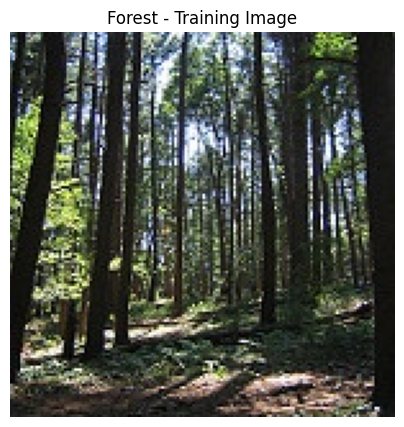

Image dimensions: (150, 150)


In [ ]:

from PIL import Image

forest_folder = TRAIN_DIR / "forest"

image_files = [
    p for p in forest_folder.iterdir()
    if p.suffix.lower() in image_extensions
]

first_image = Image.open(image_files[0]).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(first_image)
plt.title("Forest - Training Image")
plt.axis("off")
plt.show()

print("Image dimensions:", first_image.size)


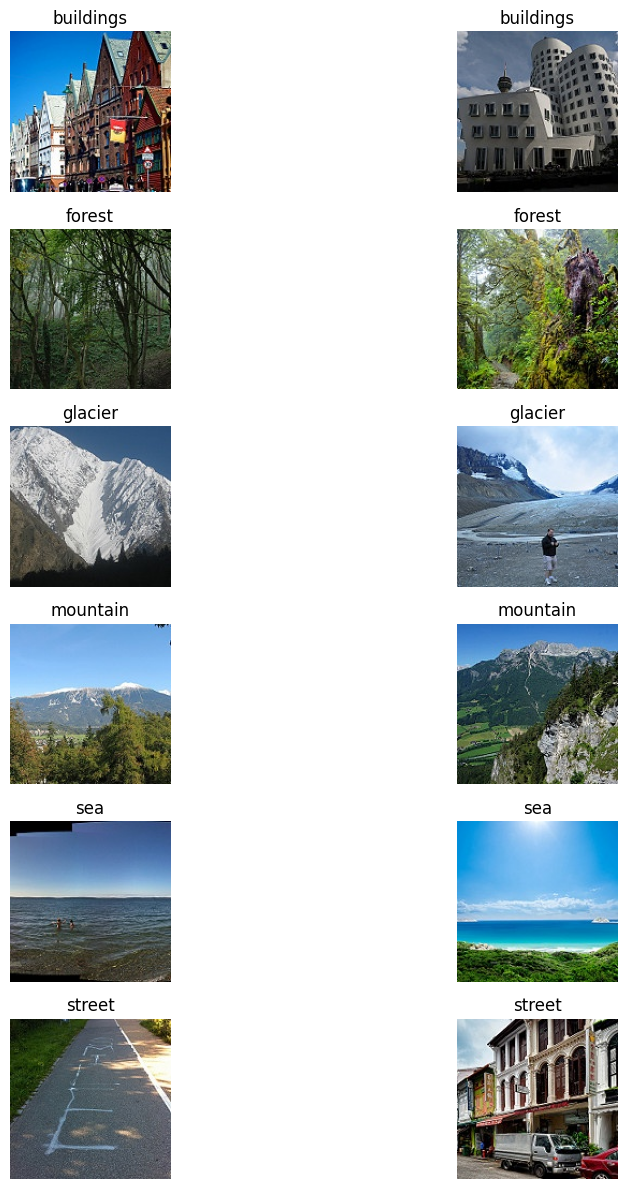

In [ ]:

# STEP 1: Display two images from each category

import random
from PIL import Image

random.seed(42)

plt.figure(figsize=(12, 12))

for class_index, class_name in enumerate(class_names):

    # Find the folder for this category
    class_folder = TRAIN_DIR / class_name

    # Find all JPG images
    image_files = list(class_folder.glob("*.jpg"))

    # Randomly choose two images
    selected_images = random.sample(image_files, 2)

    for image_index, image_path in enumerate(selected_images):

        # Open the image
        image = Image.open(image_path).convert("RGB")

        # Position it in our 6-row, 2-column grid
        position = class_index * 2 + image_index + 1

        plt.subplot(6, 2, position)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# STEP 2: Count images in every category

class_counts = {}

for class_name in class_names:

    class_folder = TRAIN_DIR / class_name

    count = len(list(class_folder.glob("*.jpg")))

    class_counts[class_name] = count

# Convert our results into a table
df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=["Category", "Number of Images"]
)

display(df_counts)

print("Total training-folder images:", sum(class_counts.values()))


,Category,Number of Images
0,buildings,2191
1,forest,2271
2,glacier,2404
3,mountain,2512
4,sea,2274
5,street,2382


Total training-folder images: 14034


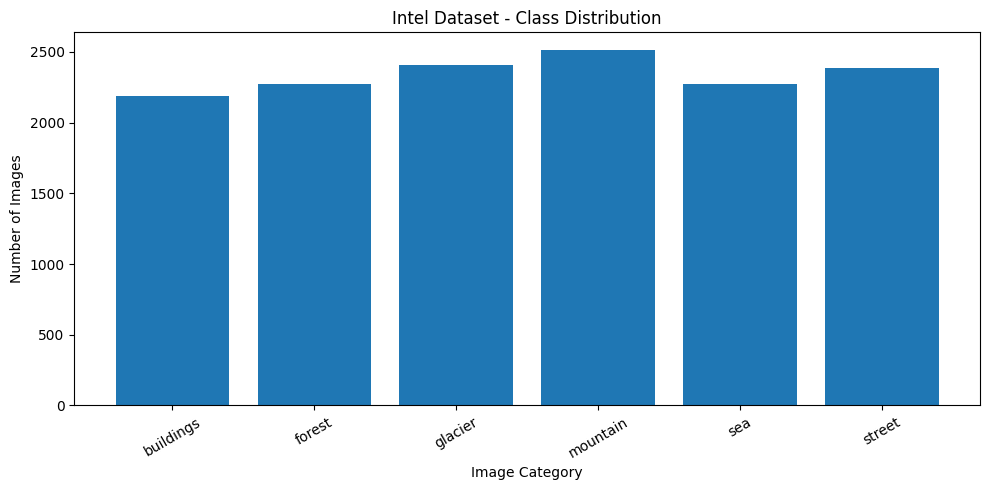

In [ ]:

# STEP 3: Create a class distribution chart

plt.figure(figsize=(10, 5))

plt.bar(
    df_counts["Category"],
    df_counts["Number of Images"]
)

plt.title("Intel Dataset - Class Distribution")
plt.xlabel("Image Category")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
